## Homework 2 - Phase I & II Analysis Using CUSUM and EWMA Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 10, 2026 via D2L**

## Instructions:

Buster's Sports Bar & Grill runs a busy draft beer program, pouring a house lager through a long-draw, CO2-driven tap system. State regulations require that a pint be poured within a fairly tight volume tolerance, and management has its own reasons to care about consistency too: an overpour on every pint adds up to real lost profit over a month, while a noticeable underpour draws customer complaints and bad reviews. The general manager has asked your quality control team to investigate the pour consistency at the bar's main tap station.

Pours are measured directly from the tap using a calibrated in-line flow meter, in ounces. The general manager has flagged a specific concern: as a CO2 regulator ages, line pressure can creep downward very gradually over weeks or months, producing more foam and a slightly smaller liquid pour -- a small, **sustained** drift, rather than a sudden jump. A chart that's only good at catching a sudden shift could easily miss this kind of slow creep until it's been happening for a long time. Pour volume is treated as a continuous, normally-distributed quality characteristic for this assignment.

Your team pulls a baseline (Phase I) sample of pour data from the tap right after a fresh regulator was installed: 5 pints sampled at random each shift, for 25 consecutive shifts. After validating statistical control, the team designs an appropriate CUSUM and EWMA monitoring scheme and applies it to 20 additional shifts of data (Phase II), collected several months later, to determine whether the aging regulator is already producing a detectable drift.

## Key Specifications

| Quantity | Value |
|---|---|
| Target pour volume | 16.00 oz |
| Lower Specification Limit (LSL) | 15.80 oz |
| Upper Specification Limit (USL) | 16.20 oz |
| Subgroup size (n) | 5 pints per shift |
| Phase I subgroups (m) | 25 shifts |
| Phase II subgroups (m) | 20 shifts |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

The analysis that we are running would be to determine the pour rate consistency at a local sports bar. Our team needs to ensure that the pour is not too far over or under the expected rate.

### Q2: Identify the quality characteristic your team will monitor, and classify its units and measurement scale.

The characteristic that we will monitor for quality is going to be the pour volume. It will be measured in oz, with our aim to be around 16 oz, and will be pulled multiple times a shift at random for a total of 25 shifts.

### Q3: Briefly describe why a CUSUM and EWMA chart would be appropriate in this scenario, given the general manager's specific concern about the aging CO2 regulator. What are the limitations of these charts?

The reason why a CUSUM or EWMA chart would be appropriate is due to these processes are able to measure tighter deviations away from our target than say Shewhart. This means that any slight deviations will be flagged, which allows us to determine whether there is a consistent issue that falls within our control limits but can potentially still be measured as a pattern.

The limitations of these charts however would be...

## Analyze

### Q4: Read the Phase I data into R. Calculate and report the subgroup means and ranges, and use them to estimate the process mean and process standard deviation.

In [ ]:
## Q4 Code ##

## Clone repository and set wd ##
user_name <- "a-gidding"
repo_name <- "STAT-7110-Quality-Control"
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}

setwd("/content/STAT-7110-Quality-Control/Assignments/HW2")



[1] "Repository already cloned to Colab."


In [ ]:
## load libraries and read in the data ##

library(tidyverse)
library(readxl)
library(qcc)
library(dplyr)

pour_df <- read_excel("BustersSportsBar_PhaseI.xlsx")

## now that data is in, calculate subgroup means and ranges ##

nrow(pour_df) ## to get an idea of how many means we should have ##
pour_mean <- rowMeans(pour_df)
print(pour_mean)

pour_range <- pour_df %>%
  rowwise() %>%
  mutate(range_diff = max(c_across(`Pour1`:`Pour5`), na.rm = TRUE) -
                       min(c_across(`Pour1`:`Pour5`), na.rm = TRUE)) %>%
  ungroup()

print(pour_range)

## use pour mean and pour range to estimate process mean and standard deviation ##

mu0 <- mean(pour_df$Shift)
sigma_hat <- sd(pour_df$Shift)
print(mu0)
print(sigma_hat)

[1] 25

 [1] 13.57420 13.71332 13.87615 14.05648 14.15625 14.36480 14.54453 14.74598
 [9] 14.88900 15.04020 15.20487 15.08987 15.56553 15.71842 15.83870 16.03462
[17] 16.21260 16.40262 16.49638 16.68375 16.91732 17.02122 17.24357 17.36255
[25] 17.55038
# A tibble: 25 × 7
   Shift Pour1 Pour2 Pour3 Pour4 Pour5 range_diff
   <dbl> <dbl> <dbl> <dbl> <dbl> <dbl>      <dbl>
 1     1  16.0  16.1  16.2  16.0  16.1     0.247 
 2     2  16.1  16.0  16.1  16.1  16.0     0.0783
 3     3  16.1  16.0  16.1  16.1  16.1     0.0801
 4     4  16.0  16.2  16.1  16.0  16.0     0.179 
 5     5  16.0  16.0  16.0  16.0  16.0     0.0641
 6     6  16.1  16.1  16.0  15.9  16.1     0.202 
 7     7  16.1  16.1  16.0  16.0  16.0     0.155 
 8     8  16.2  16.0  16.1  16.0  16.1     0.220 
 9     9  16.1  16.1  16.0  16.0  16.1     0.193 
10    10  16.1  16.1  16.0  16.0  16.0     0.0942
# ℹ 15 more rows
[1] 13
[1] 7.359801


### Q5: Construct a Phase I $R$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.

THe chart does not show evidence of statistical control due to the observations that occur during Shift 19. This shift appears to have points that fall either too high or too low for our control limits, with this pour being greater than 0.4 too large or too low for our expectations.

After removing point 19, we can see that there is statistical control. However, we can see that there is not a consistent trend either above or below our expected center. This is something we will want to consider as we move forward with our evaluations

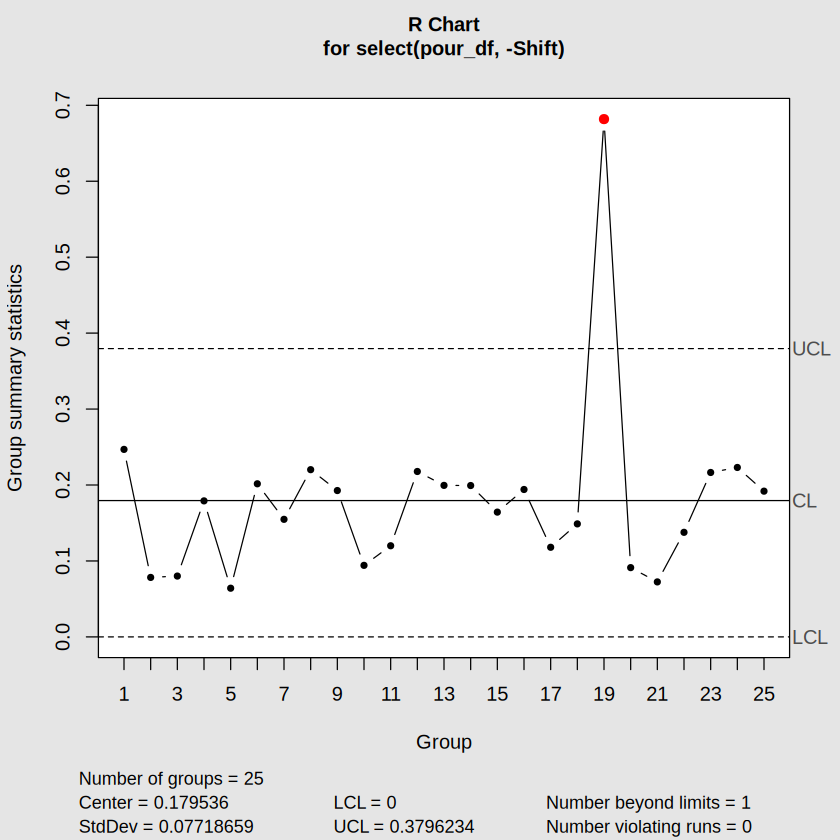

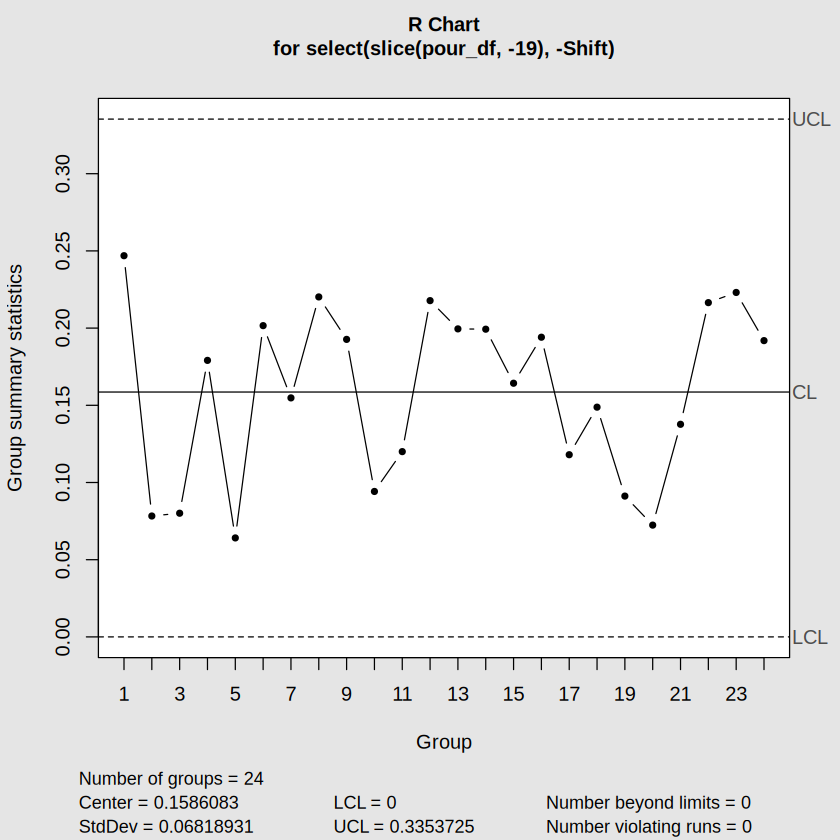

In [ ]:
## Q5 Code ##

## construct the R chart based on the information found above ##
phase1_r <- qcc(pour_df |> select(-`Shift`),
                 type = "R",
                 plot = TRUE)

phase1_rcleaned <- qcc(pour_df |> slice(-19)|> select(-`Shift`),
                 type = "R",
                 plot = TRUE)

### Q6: Using only the subgroups retained after Q5, construct the Phase I $\bar{X}$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.

This chart does not show statistical control either. We see a significant underpour during shift number 12.

After removing point number 12, our process does appear to establish statistical control. With this in mind, we can still see a bit of variation between our points that is not consistently above or below our center. With that being considered, currently, it still falls within our upper and lower control limits and would require further evaluation to determine whether there is a significant issue.

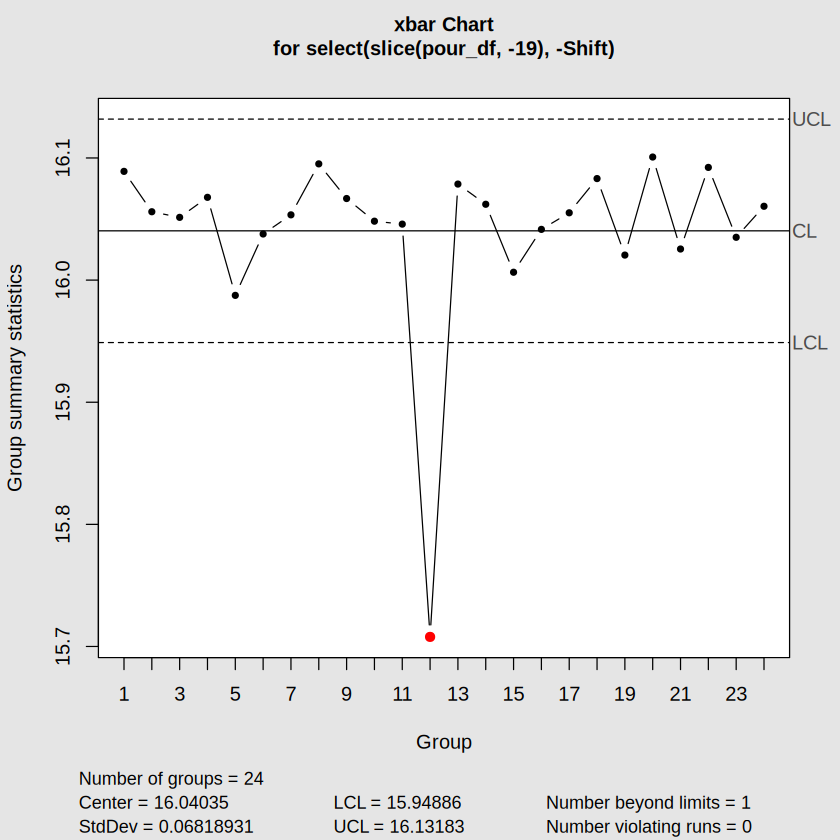

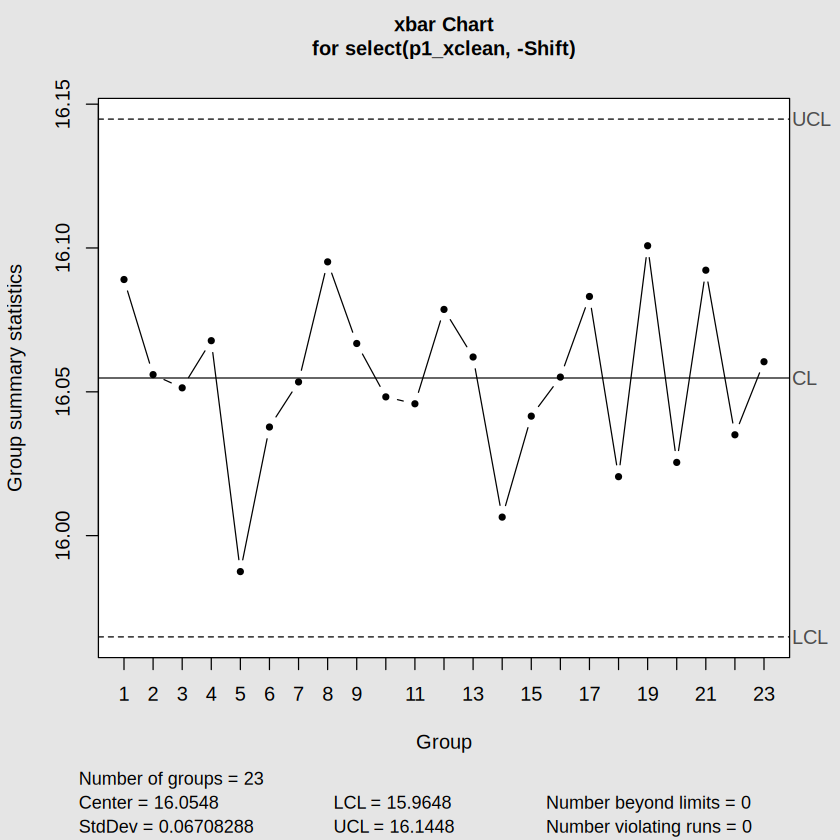

In [ ]:
## Q6 Code ##

phase1_xbar <- qcc(pour_df |> slice(-19) |> select(-`Shift`),
                   type = "xbar",
                   plot = TRUE)

p1_xclean <- pour_df |>
  slice(-c(19, 12))

phase1_xcleaned <- qcc(p1_xclean |> select(-`Shift`),
                   type = "xbar",
                   plot = TRUE)

### Q7: Using your final Phase I estimates of the process mean and process standard deviation, perform a process capability analysis against the specification limits given above. Report and interpret $PCR$, $C_p$, $C_{pk}$, and $C_{pm}$. Is the process capable of meeting specification? Is it well-centered?

After running the process capability analysis, we are able to see that our Cp value is 0.99, PCR is , Cpk is 0.72 and Cpm os 0.76. The meaning of this, since all of our numbers fall below one is that our process currently is incapable. It is not well centered, as most of our data falls above the target mean of 16 oz.


Process Capability Analysis

Call:
process.capability(object = phase1_xcleaned, spec.limits = c(15.8,     16.2), target = 16, nsigmas = 3)

Number of obs = 115          Target = 16
       Center = 16.05           LSL = 15.8
       StdDev = 0.06708         USL = 16.2

Capability indices:

       Value    2.5%   97.5%
Cp    0.9938  0.8649  1.1225
Cp_l  1.2661  1.1190  1.4132
Cp_u  0.7215  0.6277  0.8152
Cp_k  0.7215  0.6098  0.8332
Cpm   0.7696  0.6521  0.8870

Exp<LSL 0%	 Obs<LSL 0%
Exp>USL 1.5%	 Obs>USL 2.6%


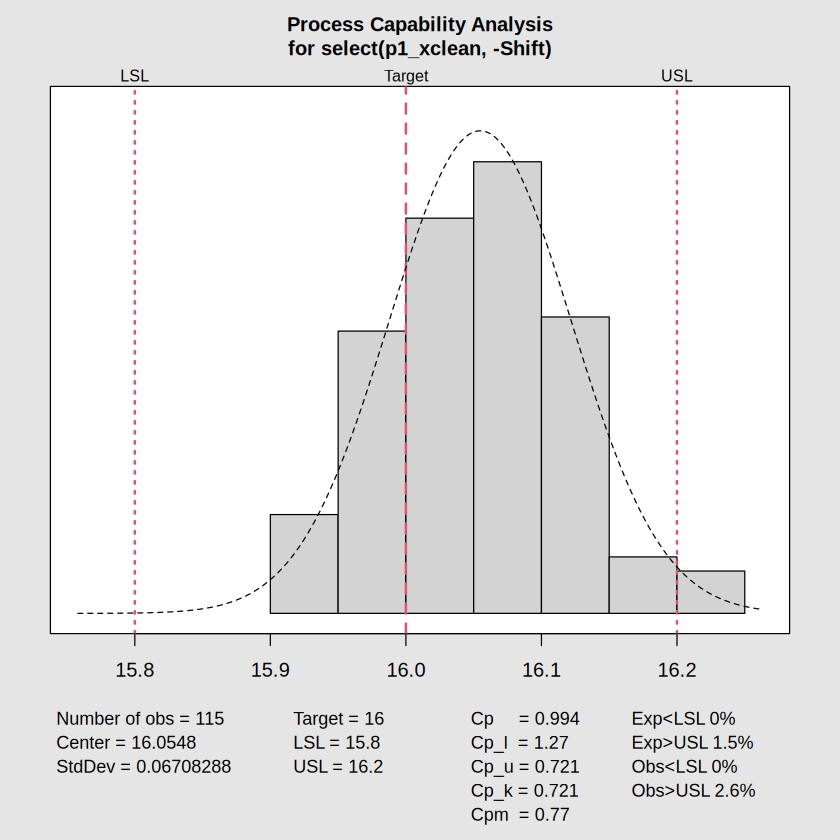

In [ ]:
## Q7 Code ##

process.capability(
  phase1_xcleaned,
  spec.limits = c(15.8, 16.2),
  target = 16,
  nsigmas = 3
)


## Improve

### Q8: The general manager wants a monitoring scheme that reliably detects a sustained shift of about one process standard deviation (representing early-stage regulator drift) while keeping the in-control ARL around 370-500. Using the design guidance from lecture, select and briefly justify: (a) the CUSUM slack value $K$ and decision interval $H$, and (b) the EWMA smoothing constant $\lambda$ and width $L$, that you will carry forward into your Phase II monitoring plan.

## Control

### Q9: Read the Phase II data into R. Using your final Phase I estimates from Q6 and the CUSUM parameters you selected in Q9, construct the Phase II CUSUM chart. Does the chart signal an out-of-control condition? If so, at which shift number?

The CUSUM chart that we created does signal an out of control condition. It specficially shifts to out of control around point 10, however, we can see that the process was moving out of the limits almost immediately, trending upwards as early as observation number 3.

 [1] 13.57630 13.67975 13.86383 14.01380 14.23518 14.38972 14.52877 14.66418
 [9] 14.82358 15.01900 15.17440 15.37490 15.50653 15.65475 15.82630 16.04025
[17] 16.17360 16.31463 16.49237 16.66477


List of 14
 $ call             : language cusum(data = pour2, sizes = 5, center = mu0, decision.interval = h, se.shift = k *      2, plot = T)
 $ type             : chr "cusum"
 $ data.name        : chr "pour2"
 $ data             : num [1:20, 1:6] 1 2 3 4 5 6 7 8 9 10 ...
  ..- attr(*, "dimnames")=List of 2
 $ statistics       : Named num [1:20] 13.6 13.7 13.9 14 14.2 ...
  ..- attr(*, "names")= chr [1:20] "1" "2" "3" "4" ...
 $ sizes            : num [1:20] 5 5 5 5 5 5 5 5 5 5 ...
 $ center           : num 13
 $ std.dev          : num 2.84
 $ pos              : num [1:20] 0 0.0358 0.2168 0.5159 0.9896 ...
 $ neg              : num [1:20] 0 0 0 0 0 0 0 0 0 0 ...
 $ head.start       : num 0
 $ decision.interval: num 5
 $ se.shift         : num 1
 $ violations       :List of 2
 - attr(*, "class")= chr "cusum.qcc"

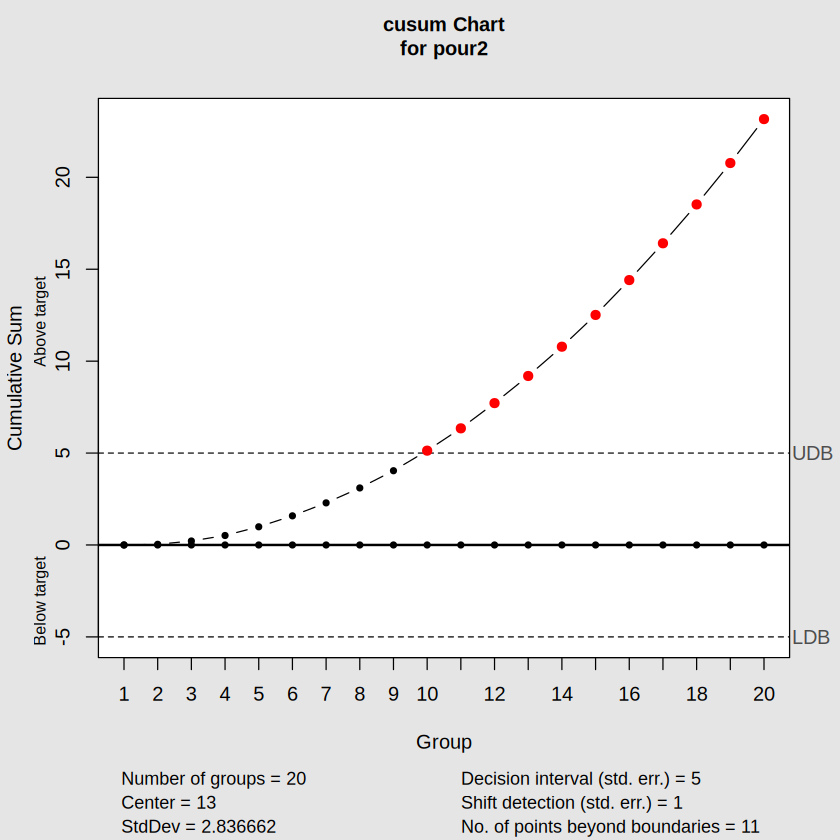

In [ ]:
## Q9 Code ##

## read in the phase 2 data ##

pour2 <- read_excel("BustersSportsBar_PhaseII.xlsx")
## standarizing the row means, and creating the C+ and C- variables required to run a cusum ##
k <- 0.5
h <- 5

pour2_mean <- rowMeans(pour2)
print(pour2_mean)

z_means <- (pour2_mean - mu0)/(sigma_hat/sqrt(5))

CUSUM_df <- tibble(Means = z_means)

pour_cusum <- CUSUM_df |>
  mutate(C_plus = Means-k,
         C_minus = -k-Means)

## use qcc package to create the chart ##

cusum(pour2,sizes=5,center=mu0,se.shift=k*2,
      decision.interval = h,plot=T)

### Q10: Using your final Phase I estimates from Q6 and the EWMA parameters you selected in Q8, construct the Phase II EWMA chart. Does the chart signal an out-of-control condition? If so, at which shift number?

The EWMA chart also shows that the process is out of control. This chart shows an earlier shift out of control than what is indicated by our CUSUM chart. We are able to see that the process shifts out of control around point number 2, which is around where we saw the beginning of the shift for our CUSUM chart.

List of 15
 $ call      : language ewma(data = pour2, center = 16, lambda = 0.2, nsigmas = 2.962)
 $ type      : chr "ewma"
 $ data.name : chr "pour2"
 $ data      : num [1:20, 1:6] 1 2 3 4 5 6 7 8 9 10 ...
  ..- attr(*, "dimnames")=List of 2
 $ statistics: Named num [1:20] 13.6 13.7 13.9 14 14.2 ...
  ..- attr(*, "names")= chr [1:20] "1" "2" "3" "4" ...
 $ sizes     : int [1:20] 6 6 6 6 6 6 6 6 6 6 ...
 $ center    : num 16
 $ std.dev   : num 2.6
 $ x         : int [1:20] 1 2 3 4 5 6 7 8 9 10 ...
 $ y         : Named num [1:20] 15.5 15.1 14.9 14.7 14.6 ...
  ..- attr(*, "names")= chr [1:20] "1" "2" "3" "4" ...
 $ sigma     : num [1:20] 0.213 0.272 0.304 0.323 0.335 ...
 $ lambda    : num 0.2
 $ nsigmas   : num 2.96
 $ limits    : num [1:20, 1:2] 15.4 15.2 15.1 15 15 ...
  ..- attr(*, "dimnames")=List of 2
 $ violations: Named int [1:11] 2 3 4 5 6 7 8 9 10 11 ...
  ..- attr(*, "names")= chr [1:11] "2" "3" "4" "5" ...
 - attr(*, "class")= chr "ewma.qcc"

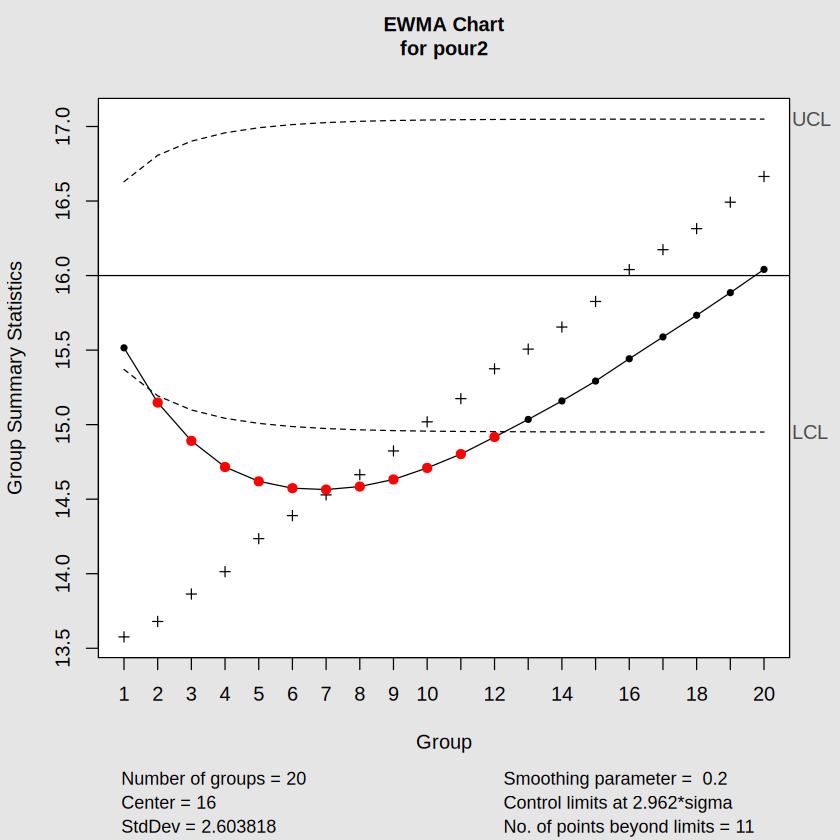

In [ ]:
## Q10 Code ##
lambda <- 0.2

sd_ewma <- vector('double',length=nrow(pour2))

for(i in 1:length(sd_ewma)){

  sd_ewma[i] <- sigma_hat^2/5*(lambda/(2-lambda))*(1-(1-lambda)^(2*i))

}

ewma(pour2,center=16,lambda=0.2,nsigmas=2.962)

### Q11: Compare the results of Q9 and Q10. Which chart detected the shift more quickly, if either? Is this consistent with what you would expect, given what you know about the relative sensitivity of CUSUM and EWMA charts to small, sustained shifts? Briefly explain.

When reviewing the two charts, we can very clearly see the shift sooner using the EWMA chart. This shows the shift as soon as it starts occurring rather than when it is already outside of the limits like the CUSUM chart did. This is consistent with what I would expect of both of these charts since they are more sensitive to changes, but the EWMA chart signals faster and is generally more liklely to cue a false alram. The only reason that we can be fairly sure that this isn't a false alarm from our EWMA chart is due to the fact that the shift is consistent with what our data has shown from phase one and earlier tests within phase two.

In [ ]:
## Q11 Code ##

### Q13: Provide an overview of the results that the general manager can provide to Buster's ownership. Does the CO2 regulator need to be replaced ahead of schedule, or can it run as planned?

For the expected pours of the tap at Busters, we can see that there is a consistently inconsistent pour. This inconsistency sits above the 16 oz at least after monitoring that occurs after our initial 25 shifts from Phase 1.Since these shifts were already initially present and were persistent after the second phase of monitoring, I recommend that the ownership proceeds with replacing the C02 regulator ahead of schedule to provide more consistent service to their customer base.